# T1. The price on a problem with an exact solution

This notebook belongs to the toolbox's under-the-hood track. It runs the workflow on the paper's running example, a
small problem whose exact solution is known, **without training anything**, so that what the price does can be
checked against the exact answer. It needs only `numpy` and `scipy`. You will

1. state a budget problem and a deployment requirement,
2. see what the clipped barrier reward does and check the identity the paper turns on,
3. get a plan: a starting price, a validation budget, and the conditions under which another method is better,
4. evaluate a few hand-made candidates and place them against the grid benchmark,
5. validate a candidate at its horizon and read the report.

Notebook T2 trains a learner through the same wrapper. Results are cited by their titles in the paper,
*The Price of Failure Risk: Clipped Barrier Policy Gradients with Convex Regularization*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import barrierpg
from barrierpg import BudgetSpec, Requirement, Stage, plan, evaluate, interpret, LogBarrier
from barrierpg.examples.wear import WearModel, make_wear_env, standing_still_policy, IncumbentRule, EXACT_FRONTIER, EXACT_BARRIER

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
print("barrierpg", barrierpg.__version__, "| checked against the paper's", barrierpg.PAPER["checked_against"])

barrierpg 0.9.0 | checked against the paper's revision 77 (2026-11-18)


## The problem: an asset operated under a wear allowance

An asset earns revenue in proportion to its **operating rate** $a\in[0,1]$ and a market price index $s$.
Each unit of throughput consumes a random part of a **wear allowance** $b=1$. Exhausting the allowance
before the next maintenance access is a **breakdown**. Maintenance access arrives with probability
$1-\beta=0.05$ per period, so the **geometric risk** $q_\beta=\mathbb E[\beta^\tau 1\{\tau<\infty\}]$ is
exactly the probability of a breakdown before access. Standing still never fails and earns nothing;
every positive rate can fail, because the wear shock is unbounded. This is the paper's running example.

`BudgetSpec` states the budget, the utility discount $\beta$ and a valid upper bound $\bar u$ on the one-step
utility. Every certificate needs $\bar u$.

In [2]:
model = WearModel()
spec = model.spec(ubar=1.0)
print(spec)

BudgetSpec(budgets=(1.0,), beta=0.95, ubar=1.0, gammas=(1.0,), u_minus=0.0, horizon=None)


## What the clipped barrier reward does

The wrapper carries the remaining reserve $z$ in the state and replaces the reward by
$$r_m=\max\{-m,\;u-B(z')\},\qquad B(z')=\theta\log(1+b/z'),$$
with $z'$ the reserve after the action. An unbounded barrier gives every exploratory policy the value $-\infty$;
clipping at $-m$ keeps returns finite. From failure onward every reward is $-m$, so $m$ is a **price of failure
risk**: one unit of geometric risk costs $m/(1-\beta)$. Before failure, the barrier subtracts an **interior loss**
that keeps a reserve; a failure-only price ($\theta=0$) charges nothing before failure.

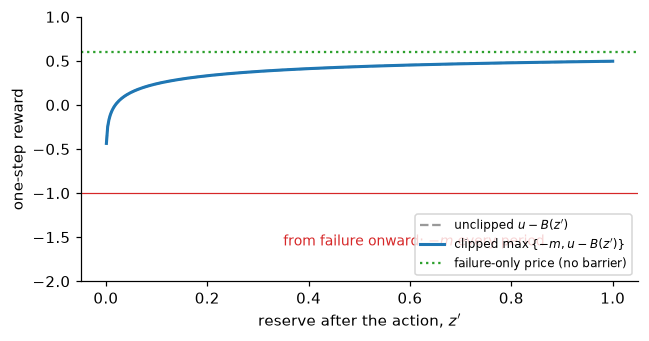

In [3]:
u, m, theta = 0.6, 1.0, 0.15
z = np.linspace(1e-3, 1.0, 400)
B = np.array([LogBarrier(theta, [1.0])([zz]) for zz in z])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(z, u - B, color="0.6", ls="--", label="unclipped $u-B(z')$")
ax.plot(z, np.maximum(-m, u - B), color="C0", lw=2, label="clipped $\\max\\{-m, u-B(z')\\}$")
ax.axhline(u, color="C2", ls=":", label="failure-only price (no barrier)")
ax.axhline(-m, color="C3", lw=0.8)
ax.annotate("from failure onward: $-m$ every period", (0.35, -m), xytext=(0.35, -1.6), color="C3", fontsize=9)
ax.set_ylim(-2, 1); ax.set_xlabel("reserve after the action, $z'$"); ax.set_ylabel("one-step reward"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## The identity behind every result

Splitting the discounted sum of clipped rewards at the failure time gives the exact identity
$$V_m=U-\mathcal I_m-\frac{m}{1-\beta}\,q_\beta ,$$
with $U$ the **stopped utility** (earned before failure) and $\mathcal I_m$ the interior loss. Let us check it
on simulated episodes: the wrapper records the clipped return of each episode, and `evaluate` computes the
right-hand side from $U$, $\mathcal I_m$ and the failure indicator.

The wear wrapper uses **geometric stopping**: each period ends the episode with probability $1-\beta$.
A learner with discount one then optimizes the discounted objective exactly, and the failure indicator of an
episode has probability $q_\beta$.

In [4]:
barrier_stage = Stage(m=1.0, theta=0.1)
rule = IncumbentRule(span=1.5, std=0.1, seed=0)          # a rate proportional to the remaining allowance
ev = evaluate(lambda: make_wear_env(barrier_stage, model), rule, 5000, spec=spec, stage=barrier_stage, seed=0)
print(ev.summary())
print(f"\nmean clipped return {ev.clipped_returns.mean():.4f}  vs  U - I_m - m q/(1-beta) = {ev.V_m:.4f}")
print("largest per-episode difference:", float(np.max(np.abs(ev.clipped_returns - ev.V_episodes))))

n=5000: p_T censored by the geometric clock (370 failures counted for q_beta), q_beta=0.074, U=3.991±0.031, I_m=2.991, V_m=-0.4795±0.1, mean length 19.0
small reserve (min reserve <=): 0.02b: 0.101, 0.05b: 0.151, 0.1b: 0.225, 0.2b: 0.348

mean clipped return -0.4795  vs  U - I_m - m q/(1-beta) = -0.4795
largest per-episode difference: 1.4210854715202004e-14


## State the requirement, then plan

The requirement comes first: the breakdown probability within $T+1=20$ periods must stay below $\alpha=5\%$, and
the validation may be wrong with probability $\zeta=5\%$. Several candidates will be validated, so the error is
shared by a **family** of statements.

`plan` turns this into a configuration with reasons. It derives a conservative starting price from the
**price–risk bound** (a part of the paper's *Fixed price of failure risk*), using a comparison policy that never fails
(standing still) and an upper bound on the utility at stake. It also sizes the validation sample and states the
cases of the paper's *Which formulation to prefer* in which another method is the better choice.

In [ ]:
req = Requirement(T=19, alpha=0.05, zeta=0.05, family=6)   # six candidates will be inspected
sup_U = spec.ubar / (1 - spec.beta)    # an upper bound on the continuous-model stopped utility
p = plan(spec, req, sup_U=sup_U, expected_failure_rate=0.01, validation_H=300, validation_N=20000,
         allowance_error_known=False, failure_permissible_at_deployment=True, model_known_and_small=True)
print(p.explain())

The model is known, so dynamic programming on a grid gives a benchmark for the candidates.

This calculation uses a uniform utility bound. An optimization gap still has to be justified, and validation assesses the returned policy. Below we use $m=1$.

## Candidates against the grid benchmark

A **candidate** is one fixed policy that may be deployed. Here the candidates are hand-made rules: standing
still, and rules that run at a rate proportional to the remaining allowance, $a=\min\{1, z/(\text{span}\cdot b)\}$.
The plotted points are the grid-based wear benchmark across prices. A true fixed-price optimum is optimal at its attained risk under the conditions of *Fixed price of failure risk*.

In [6]:
stage = Stage(m=1.0)
env = lambda: make_wear_env(stage, model)
candidates = {"standing still": standing_still_policy}
for span in (1.0, 1.5, 2.0, 3.0, 5.0):
    candidates[f"rule, span {span:g}"] = IncumbentRule(span=span, std=0.1, seed=1)
evals = {name: evaluate(env, pol, 6000, spec=spec, stage=stage, seed=10, T=19) for name, pol in candidates.items()}
for name, e in evals.items():
    print(f"{name:14s} q_beta = {e.q_beta:.4f}   U = {e.U:.3f}   reserve below 5% of b =  {e.near[0.05]:.3f}")

standing still q_beta = 0.0000   U = 0.000   reserve below 5% of b =  0.000
rule, span 1   q_beta = 0.1723   U = 4.648   reserve below 5% of b =  0.298
rule, span 1.5 q_beta = 0.0710   U = 3.971   reserve below 5% of b =  0.149
rule, span 2   q_beta = 0.0365   U = 3.467   reserve below 5% of b =  0.076
rule, span 3   q_beta = 0.0100   U = 2.760   reserve below 5% of b =  0.024
rule, span 5   q_beta = 0.0013   U = 1.959   reserve below 5% of b =  0.005


In [ ]:
qf = np.array([v[0] for k, v in EXACT_FRONTIER.items()]); Uf = np.array([v[1] for k, v in EXACT_FRONTIER.items()])
order = np.argsort(qf)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(qf[order], Uf[order], color="0.2", lw=1.5, label="grid benchmark (failure-only prices)")
qb = [v[0] for v in EXACT_BARRIER.values()]; Ub = [v[1] for v in EXACT_BARRIER.values()]
ax.plot(qb, Ub, color="C2", ls="--", marker=".", label="grid benchmark, $\\theta=0.1$")
for name, e in evals.items():
    if name != "standing still":
        ax.plot(e.q_beta, e.U, "o", color="C0", ms=5)
        ax.annotate(name.replace("rule, ", ""), (e.q_beta, e.U), textcoords="offset points", xytext=(4, -10), fontsize=7)
ax.axvline(0.05, color="C3", ls=":", lw=1, label="tolerance 0.05")
ax.set_xscale("log"); ax.set_xlabel("breakdown probability $q_\\beta$"); ax.set_ylabel("stopped utility $U$")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

Compare the rules' estimated utility at their measured risk with the grid curves. Notebook T2 measures the protection under a smaller allowance.

## A plug-in price–risk calculation

We plug the no-price benchmark utility into the price–risk expression, as in the wear study. The comparison assumes zero gap for illustration. The grid data do not establish those assumptions for the continuous model.

In [ ]:
from barrierpg.frontier import Run, check_runs
runs = [Run(m=mm, q_beta=q, U=U, label="exact") for mm, (q, U) in EXACT_FRONTIER.items() if mm > 0]
chk = check_runs(runs, beta=spec.beta, sup_U=EXACT_FRONTIER[0.0][1], delta=0.0)
print("plug-in comparison across prices:")
ms = np.array([r["m"] for r in chk.table]); qs = np.array([r["q_beta"] for r in chk.table]); law = np.array([r["price_risk_bound"] for r in chk.table])
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.loglog(ms, qs, "o-", color="0.2", label="grid benchmark risk")
ax.loglog(ms, law, "--", color="C1", label="plug-in estimate")
ax.set_xlabel("price $m$"); ax.set_ylabel("$q_\\beta$"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print("plug-in estimate / benchmark risk at m = 1, 10:", [round(float(l / q), 1) for l, q, mm in zip(law, qs, ms) if mm in (1.0, 10.0)])

The bound has the right dependence on the price, order $1/m$, and is conservative by a factor of about twenty.

## Validate the candidate that would be deployed

Validation is the deployment decision. Draw fresh episodes of the fixed candidate and compute a one-sided exact
binomial upper bound on its failure probability. Zero failures in $N$ episodes certify the bound # $1-\zeta^{1/N}$, never zero. The error $\zeta$ is split over the family of candidates inspected, before any is
selected. Failure to certify does not prove a violation.

Under geometric stopping the episode clock censors the finite-horizon risk $p_T$, so the toolbox validates
$q_\beta$ and uses $p_T\le\beta^{-T}q_\beta$. Notebook T4 shows how to validate $p_T$ directly.

In [9]:
for name, e in evals.items():
    v = e.validate(req.alpha * spec.beta ** req.T, req.zeta, req.family)
    print(f"{name:14s} {v.failures:4d} failures / {v.n}: upper bound on q_beta {v.upper:.4f} -> "
          f"{'certifies' if v.passed else 'does not certify'} p_19 <= 0.05 (zero failures would certify {v.zero_failure_bound:.4f})")

standing still    0 failures / 6000: upper bound on q_beta 0.0008 -> certifies p_19 <= 0.05 (zero failures would certify 0.0008)
rule, span 1   1034 failures / 6000: upper bound on q_beta 0.1843 -> does not certify p_19 <= 0.05 (zero failures would certify 0.0008)
rule, span 1.5  426 failures / 6000: upper bound on q_beta 0.0793 -> does not certify p_19 <= 0.05 (zero failures would certify 0.0008)
rule, span 2    219 failures / 6000: upper bound on q_beta 0.0427 -> does not certify p_19 <= 0.05 (zero failures would certify 0.0008)
rule, span 3     60 failures / 6000: upper bound on q_beta 0.0135 -> certifies p_19 <= 0.05 (zero failures would certify 0.0008)
rule, span 5      8 failures / 6000: upper bound on q_beta 0.0030 -> certifies p_19 <= 0.05 (zero failures would certify 0.0008)


## The report

`interpret` writes what the evidence establishes for one candidate and what it does not. When the optimization
error is unknown (`delta=None`), as for a hand-made rule, the report makes no optimality claim; validation is the
operative evidence.

In [ ]:
inc = evals["rule, span 3"]
rep = interpret(spec, req, stage, inc, sup_U=sup_U, delta=None, candidate_name="the span-3 rule")
print(rep.text())

## Summary

* The price sets the risk attained; it does not prescribe a level. The price–risk bound gives a safe starting price.
* The identity $V_m=U-\mathcal I_m-\tfrac{m}{1-\beta}q_\beta$ is exact; every certificate rests on it.
* Validation of the deployed candidate, with the error shared across the candidates inspected, is the deployment decision.

Next: **notebook T2** trains PPO through the wrapper and measures how close it gets to the grid benchmark.